In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("Maternal Health Risk Data Set.csv")

In [3]:
print(df['SystolicBP'].min(), df['SystolicBP'].max())

70 160


In [23]:
df.groupby('RiskLevel')[['Age','SystolicBP','DiastolicBP','BS','BodyTemp','HeartRate']].agg(['mean','min','max'])

Age          SystolicBP          DiastolicBP           \
                mean min max        mean min  max        mean min  max   
RiskLevel                                                                
0          26.923267  10  70  105.797030  70  129   72.522277  49  100   
1          28.363095  10  60  113.154762  70  140   74.232143  50  100   
2          36.216912  12  65  124.194853  83  160   85.073529  60  100   

                  BS              BodyTemp               HeartRate          
                mean  min   max       mean   min    max       mean min max  
RiskLevel                                                                   
0           7.216906  6.0  11.0  98.370792  98.0  103.0  73.096535  60  88  
1           7.795744  6.0  18.0  98.833333  98.0  103.0  74.175595  60  88  
2          12.122610  6.1  19.0  98.899265  98.0  103.0  76.742647  60  90

In [10]:
df['RiskLevel'] = df['RiskLevel'].map({
    'low risk': 0,
    'mid risk': 1,
    'high risk': 2
})

In [3]:
df.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [4]:
df.tail()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
1009,22,120,60,15.0,98.0,80,high risk
1010,55,120,90,18.0,98.0,60,high risk
1011,35,85,60,19.0,98.0,86,high risk
1012,43,120,90,18.0,98.0,70,high risk
1013,32,120,65,6.0,101.0,76,mid risk


In [5]:
df.shape

(1014, 7)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   str    
dtypes: float64(2), int64(4), str(1)
memory usage: 63.8 KB


In [7]:
print(df[df['HeartRate'] < 50])

     Age  SystolicBP  DiastolicBP   BS  BodyTemp  HeartRate RiskLevel
499   16         120           75  7.9      98.0          7  low risk
908   16         120           75  7.9      98.0          7  low risk


In [8]:
df = df[df['HeartRate'] >= 50]
print(f"Jumlah data setelah hapus outlier HeartRate: {df.shape[0]}")

Jumlah data setelah hapus outlier HeartRate: 1012


In [9]:
df.isnull().sum()

Age            0
SystolicBP     0
DiastolicBP    0
BS             0
BodyTemp       0
HeartRate      0
RiskLevel      0
dtype: int64

In [3]:
df.duplicated().sum()

np.int64(562)

In [8]:
df=df.drop_duplicates()

In [28]:
df.shape

(1014, 7)

In [15]:
df[df.duplicated()]

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
67,19,120,80,7.0,98.0,70,1
72,19,120,80,7.0,98.0,70,1
97,19,120,80,7.0,98.0,70,1
106,50,140,90,15.0,98.0,90,2
107,25,140,100,6.8,98.0,80,2
...,...,...,...,...,...,...,...
1009,22,120,60,15.0,98.0,80,2
1010,55,120,90,18.0,98.0,60,2
1011,35,85,60,19.0,98.0,86,2
1012,43,120,90,18.0,98.0,70,2


In [16]:
print(df.shape)

(1012, 7)


In [17]:
print(df.describe())

               Age   SystolicBP  DiastolicBP           BS     BodyTemp  \
count  1012.000000  1012.000000  1012.000000  1012.000000  1012.000000   
mean     29.899209   113.184783    76.463439     8.727619    98.666403   
std      13.473560    18.419618    13.899372     3.296583     1.372421   
min      10.000000    70.000000    49.000000     6.000000    98.000000   
25%      19.000000   100.000000    65.000000     6.900000    98.000000   
50%      26.000000   120.000000    80.000000     7.500000    98.000000   
75%      39.000000   120.000000    90.000000     8.000000    98.000000   
max      70.000000   160.000000   100.000000    19.000000   103.000000   

         HeartRate    RiskLevel  
count  1012.000000  1012.000000  
mean     74.434783     0.869565  
std       7.521857     0.807227  
min      60.000000     0.000000  
25%      70.000000     0.000000  
50%      76.000000     1.000000  
75%      80.000000     2.000000  
max      90.000000     2.000000  


In [11]:
print(df['RiskLevel'].value_counts())

RiskLevel
0    404
1    336
2    272
Name: count, dtype: int64


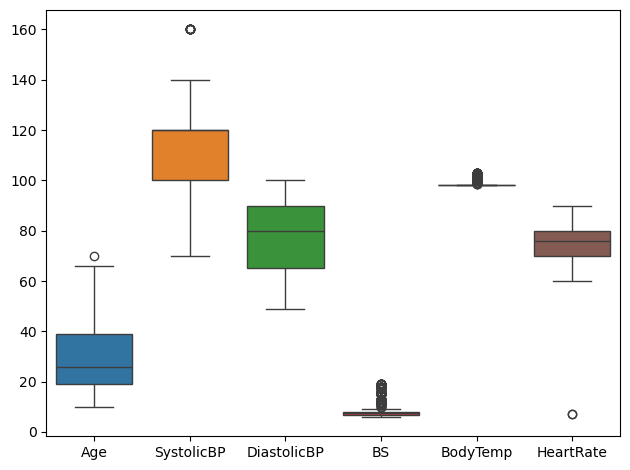

In [3]:
sns.boxplot(data=df)
plt.tight_layout()
plt.savefig('memeriksa_outlier_dengan_boxplot.png', dpi=150)
plt.show()

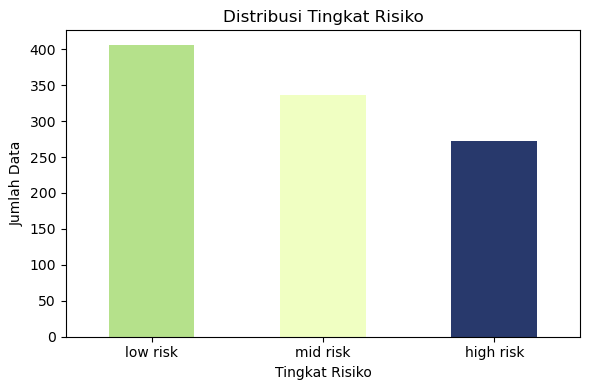

In [4]:
plt.figure(figsize=(6, 4))
colors = {'low risk':'#B5E18B', 'mid risk':'#F0FFC2', 'high risk':'#28396C'}
df['RiskLevel'].value_counts().plot(kind='bar', color=[colors[x] for x in df['RiskLevel'].value_counts().index], edgecolor='none')
plt.title('Distribusi Tingkat Risiko')
plt.xlabel('Tingkat Risiko')
plt.ylabel('Jumlah Data')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('distribusi_tingkat_risiko.png', dpi=150)
plt.show()

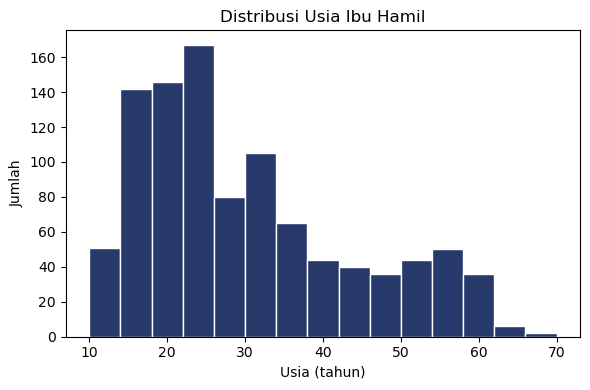

In [5]:
plt.figure(figsize=(6, 4))
plt.hist(df['Age'], bins=15, color='#28396C', edgecolor='white')
plt.title('Distribusi Usia Ibu Hamil')
plt.xlabel('Usia (tahun)')
plt.ylabel('Jumlah')
plt.tight_layout()
plt.savefig('histogram_usia.png', dpi=150)
plt.show()

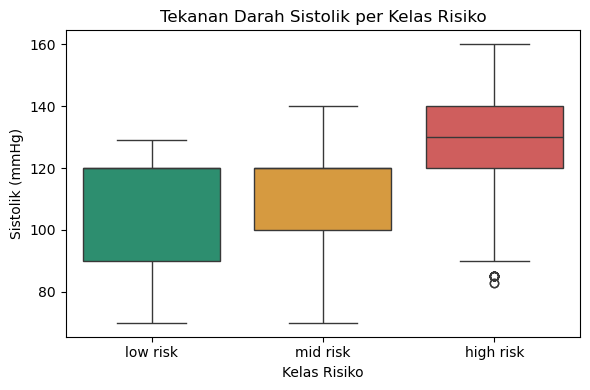

In [6]:
plt.figure(figsize=(6, 4))
sns.boxplot(
    data=df, 
    x='RiskLevel', 
    y='SystolicBP',
    hue='RiskLevel',
    order=['low risk', 'mid risk', 'high risk'],
    palette={'low risk':'#1D9E75', 'mid risk':'#EF9F27', 'high risk':'#E24B4A'},
    legend=False
)
plt.title('Tekanan Darah Sistolik per Kelas Risiko')
plt.xlabel('Kelas Risiko')
plt.ylabel('Sistolik (mmHg)')
plt.tight_layout()
plt.savefig('boxplot_sistolik.png', dpi=150)
plt.show()

In [11]:
# MODELING

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report)
from sklearn.preprocessing import LabelEncoder
import joblib

In [30]:
# 1. LOAD & PREPROCESSING
le = LabelEncoder()
df['RiskLevel'] = le.fit_transform(df['RiskLevel'])
print("Mapping kelas: ", dict(zip(le.classes_, le.transform(le.classes_))))

Mapping kelas:  {'high risk': np.int64(0), 'low risk': np.int64(1), 'mid risk': np.int64(2)}


In [12]:
# Pisah atau drop RiskLevel agar model dapat belajar untuk memprediksi RiskLevel
X = df.drop(columns='RiskLevel')
y = df['RiskLevel']

print(f"Jumlah data: {X.shape[0]} baris, {X.shape[1]} fitur")

Jumlah data: 1012 baris, 6 fitur


In [13]:
# 2. SPLIT DATA
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Data latih : {X_train.shape[0]} baris")
print(f"Data uji   : {X_test.shape[0]} baris")

Data latih : 809 baris
Data uji   : 203 baris


In [14]:
# 3. MODEL OBJECT
rf = RandomForestClassifier(
    n_estimators=100, # membuat 100 pohon decision
    max_depth=None, # kedalaman pohon tidak dibatasi
    random_state=42, # angka acak dikunci agar hasil selalu sama setiap dijalankan
    n_jobs=-1 # pakai semua core CPU agar proses lebih cepat
)

In [15]:
# 3. MODEL OBJECT
rf = RandomForestClassifier(
    n_estimators=100, 
    max_depth=None, 
    random_state=42, 
    n_jobs=-1 
)

In [16]:
# 4. K-FOLD CROSS VALIDATION (k=10)
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42) # membagi data menjadi 10 bagian dan memastikan kelas tetap seimbang. data diacak sebelum dibagi.
cv_scores = cross_val_score(rf, X, y, cv=skf, scoring='accuracy') # melatih dan menguji model sebanyak 10 kali, 9 untuk latih dan 1 untuk uji.

print(f"\nHasil 10-Fold Cross Validation:")
print(f"Akurasi tiap fold : {[round(s, 4) for s in cv_scores]}") # melihat konsistensi model di setiap iterasi
print(f"Rata-rata akurasi : {cv_scores.mean():.4f} ({cv_scores.mean()*100:.2f}%)") # performa keseluruhan model
print(f"Standar deviasi   : {cv_scores.std():.4f}") # semakin kecil semakin baik, artinya model stabil dan tidak bergantung pada pembagian data tertentu.


Hasil 10-Fold Cross Validation:
Akurasi tiap fold : [np.float64(0.902), np.float64(0.8627), np.float64(0.8416), np.float64(0.8515), np.float64(0.8317), np.float64(0.8317), np.float64(0.8515), np.float64(0.8416), np.float64(0.8614), np.float64(0.9109)]
Rata-rata akurasi : 0.8586 (85.86%)
Standar deviasi   : 0.0260


In [17]:
# 5. TRAINING MODEL FINAL DAN PREDIKSI MODEL
rf.fit(X_train, y_train)
print("\nModel final selesai dilatih!")

y_pred = rf.predict(X_test)
print("Prediksi selesai!")


Model final selesai dilatih!
Prediksi selesai!


In [18]:
# 6. EVALUASI MODEL
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted')
rec = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

In [19]:
print(f"Akurasi  : {acc:.4f} ({acc*100:.2f}%)")
print(f"Presisi  : {prec:.4f} ({prec*100:.2f}%)")
print(f"Recall   : {rec:.4f} ({rec*100:.2f}%)")
print(f"F1-Score : {f1:.4f} ({f1*100:.2f}%)")
print(f"\nClassification Report")
print(classification_report(y_test, y_pred, target_names=['Low risk', 'Mid risk', 'High risk']))

Akurasi  : 0.8374 (83.74%)
Presisi  : 0.8370 (83.70%)
Recall   : 0.8374 (83.74%)
F1-Score : 0.8361 (83.61%)

Classification Report
              precision    recall  f1-score   support

    Low risk       0.85      0.79      0.82        81
    Mid risk       0.79      0.79      0.79        67
   High risk       0.87      0.96      0.91        55

    accuracy                           0.84       203
   macro avg       0.84      0.85      0.84       203
weighted avg       0.84      0.84      0.84       203



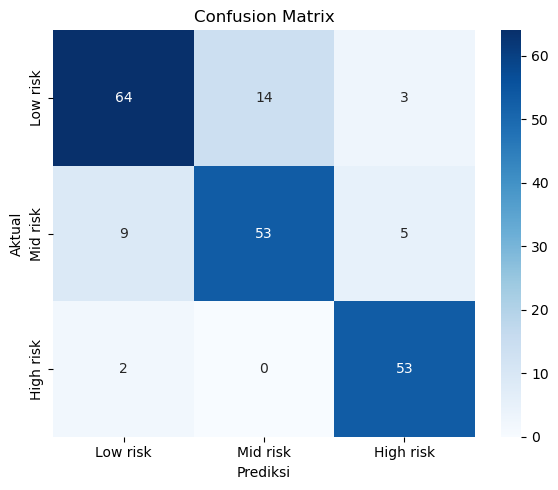

In [20]:
# 7. CONFUSION MATRIX
plt.figure(figsize=(6,5))
sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low risk', 'Mid risk', 'High risk'],
            yticklabels=['Low risk', 'Mid risk', 'High risk'])
plt.title('Confusion Matrix')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

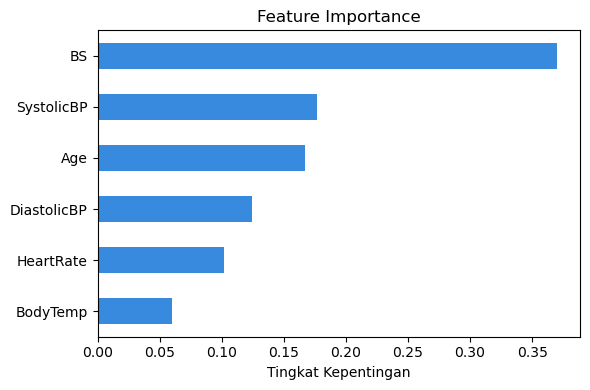

In [21]:
# 8. FEATURE IMPORTANCE
importances = pd.Series(rf.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=True)

plt.figure(figsize=(6,4))
importances.plot(kind='barh', color='#378ADD', edgecolor='none')
plt.title('Feature Importance')
plt.xlabel('Tingkat Kepentingan')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

In [ ]:
import joblib
joblib.dump(rf, 'model.pkl')
print("\nModel berhasil disimpan!")